Automated Diabetic Retinopathy Severity Classification Using Retinal Fundus Images
By: Pretom Areefin Pranto and  MD. Farhad Hossain Shishir

## Dataset: APTOS 2019 Retinal Fundus Images

**EDA → image preparation → 80/10/10 split → ResNet50 transfer learning → fine-tuning → robust evaluation → Grad-CAM**

The dataset images in the extracted archive are **224×224**.

The experiment uses an **80% training / 10% validation / 10% test** stratified split. The training pipeline uses modest image augmentation and softened class weights for the imbalanced labels. ResNet50 is initialized from ImageNet-pretrained weights, followed by a frozen-backbone stage and a low-learning-rate fine-tuning stage.

Final REPORTS: **accuracy, balanced accuracy, Macro-F1, Weighted-F1, Quadratic Weighted Kappa (QWK), ordinal MAE, within-one accuracy, bootstrap confidence intervals, confusion matrix, and Grad-CAM visualizations**.


## 1. Dependencies



In [ ]:
import os
import random
import zipfile
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASS_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Proliferative DR",
}

NUM_CLASSES = len(CLASS_NAMES)

NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Google Drive dataset setup

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET"
)

archive_matches = list(PROJECT_DIR.rglob("archive.zip"))

if len(archive_matches) == 0:
    raise FileNotFoundError(
        f"No archive.zip was found inside: {PROJECT_DIR}"
    )

if len(archive_matches) > 1:
    raise RuntimeError(
        "More than one archive.zip was found. Keep only the intended dataset archive in the project folder."
    )

ARCHIVE_PATH = archive_matches[0]
EXTRACT_DIR = PROJECT_DIR / "APTOS_extracted"
OUTPUT_DIR = PROJECT_DIR / "CSE427_progress"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Archive:", ARCHIVE_PATH)
print("Archive exists:", ARCHIVE_PATH.exists())
print("Extraction directory:", EXTRACT_DIR)
print("Output directory:", OUTPUT_DIR)

Project folder: /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET
Archive: /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/archive.zip
Archive exists: True
Extraction directory: /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/APTOS_extracted
Output directory: /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/CSE427_progress


In [ ]:
if not EXTRACT_DIR.exists() or not any(EXTRACT_DIR.iterdir()):
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print("Archive extracted.")
else:
    print("Existing extracted dataset found. Skipping extraction.")

print("\nExtracted top-level contents:")
for item in sorted(EXTRACT_DIR.iterdir()):
    print(" -", item.name)

Existing extracted dataset found. Skipping extraction.

Extracted top-level contents:
 - colored_images
 - train.csv


## 3. Load the dataset metadata


In [ ]:
LOCAL_DATASET_DIR = Path("/content/APTOS_local")
LOCAL_IMAGE_ROOT = LOCAL_DATASET_DIR / "colored_images"
LOCAL_CSV_PATH = LOCAL_DATASET_DIR / "train.csv"

SOURCE_CSV_PATH = EXTRACT_DIR / "train.csv"
SOURCE_IMAGE_ROOT = EXTRACT_DIR / "colored_images"

LOCAL_DATASET_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not LOCAL_CSV_PATH.exists():
    shutil.copy2(
        SOURCE_CSV_PATH,
        LOCAL_CSV_PATH
    )

if not LOCAL_IMAGE_ROOT.exists():
    shutil.copytree(
        SOURCE_IMAGE_ROOT,
        LOCAL_IMAGE_ROOT
    )
    print("Dataset copied to Colab local storage.")
else:
    print("Local image dataset already exists. Skipping copy.")

print("\nLocal dataset paths:")
print("CSV   :", LOCAL_CSV_PATH)
print("Images:", LOCAL_IMAGE_ROOT)

Dataset copied to Colab local storage.

Local dataset paths:
CSV   : /content/APTOS_local/train.csv
Images: /content/APTOS_local/colored_images


In [ ]:
CSV_PATH = LOCAL_CSV_PATH
IMAGE_ROOT = LOCAL_IMAGE_ROOT
df = pd.read_csv(CSV_PATH)
# Remove Severe class (original diagnosis = 3)
df = df[df["diagnosis"] != 3].copy()
# Re-map Proliferative DR from original class 4 to new class 3
df["diagnosis"] = df["diagnosis"].replace({4: 3})
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (3469, 2)
Columns: ['id_code', 'diagnosis']


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,3
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [ ]:
# Match each id_code to an image file inside colored_images.
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_files = [
    path
    for path in IMAGE_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

image_map = {path.stem: str(path) for path in image_files}
df["image_path"] = df["id_code"].map(image_map)

missing_images = df["image_path"].isna().sum()

print("Image files found:", len(image_files))
print("Images matched to train.csv:", df["image_path"].notna().sum())
print("Images missing from mapping:", missing_images)

if missing_images > 0:
    display(df[df["image_path"].isna()].head())
    raise FileNotFoundError(
        "Some train.csv image IDs could not be matched to files inside colored_images."
    )

Image files found: 3662
Images matched to train.csv: 3469
Images missing from mapping: 0


In [ ]:
image_extensions = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff"
}

image_files = [
    path
    for path in IMAGE_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

image_map = {
    path.stem: str(path)
    for path in image_files
}

df["image_path"] = df["id_code"].map(image_map)

print("Image files found:", len(image_files))
print("Images matched:", df["image_path"].notna().sum())
print("Images missing:", df["image_path"].isna().sum())

if df["image_path"].isna().any():
    display(df[df["image_path"].isna()].head())
    raise FileNotFoundError(
        "Some image IDs could not be matched to the images."
    )

Image files found: 3662
Images matched: 3469
Images missing: 0


## 4. Basic EDA

In [ ]:
print("Number of samples:", len(df))
print("\nMissing values:")
print(df[["id_code", "diagnosis", "image_path"]].isnull().sum())

print("\nDuplicate image IDs:", df["id_code"].duplicated().sum())
print("Duplicate image paths:", df["image_path"].duplicated().sum())

print("\nDiagnosis labels:", sorted(df["diagnosis"].unique()))

Number of samples: 3469

Missing values:
id_code       0
diagnosis     0
image_path    0
dtype: int64

Duplicate image IDs: 0
Duplicate image paths: 0

Diagnosis labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## 5. Class distribution

The four diagnosis values represent four severity classes.

,Class,Severity,Count,Percentage
0,0,No DR,1805,52.03
1,1,Mild,370,10.67
2,2,Moderate,999,28.80
3,3,Proliferative DR,295,8.50


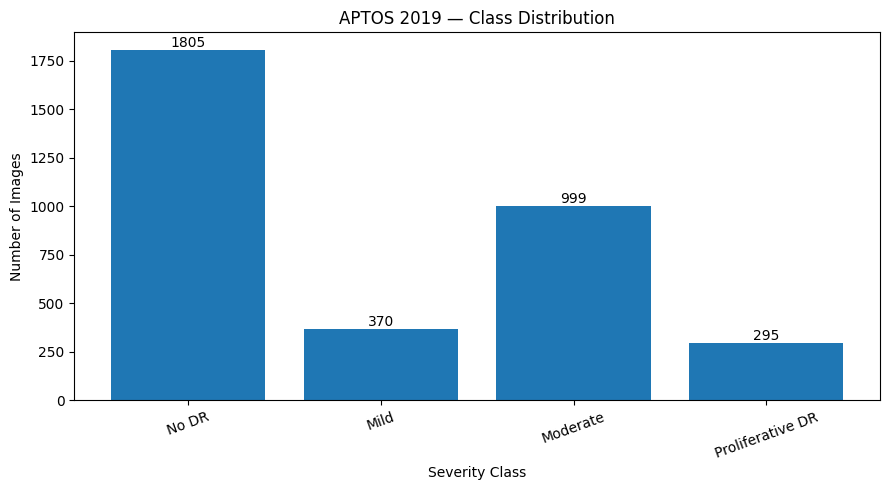

In [ ]:
class_counts = df["diagnosis"].value_counts().sort_index()

summary = pd.DataFrame({
    "Class": range(NUM_CLASSES),
    "Severity": [CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    "Count": [class_counts[i] for i in range(NUM_CLASSES)],
})

summary["Percentage"] = (
    summary["Count"] / len(df) * 100
).round(2)

display(summary)

plt.figure(figsize=(9, 5))
bars = plt.bar(
    [CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    class_counts.values
)
plt.title("APTOS 2019 — Class Distribution")
plt.xlabel("Severity Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

for bar, value in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## 6. Check the image dimensions



In [ ]:
dimension_records = []

for path in df["image_path"]:
    with Image.open(path) as image:
        width, height = image.size
    dimension_records.append((width, height))

dimensions_df = pd.DataFrame(
    dimension_records,
    columns=["width", "height"]
)

display(dimensions_df.value_counts().rename("count").reset_index())

all_224 = bool(
    (
        (dimensions_df["width"] == IMG_SIZE) &
        (dimensions_df["height"] == IMG_SIZE)
    ).all()
)

print("All images are 224×224:", all_224)

if not all_224:
    raise ValueError(
        "The current archive contains images with dimensions other than 224×224."
    )

,width,height,count
0,224,224,3469


All images are 224×224: True


## 7. Display sample images from four classes

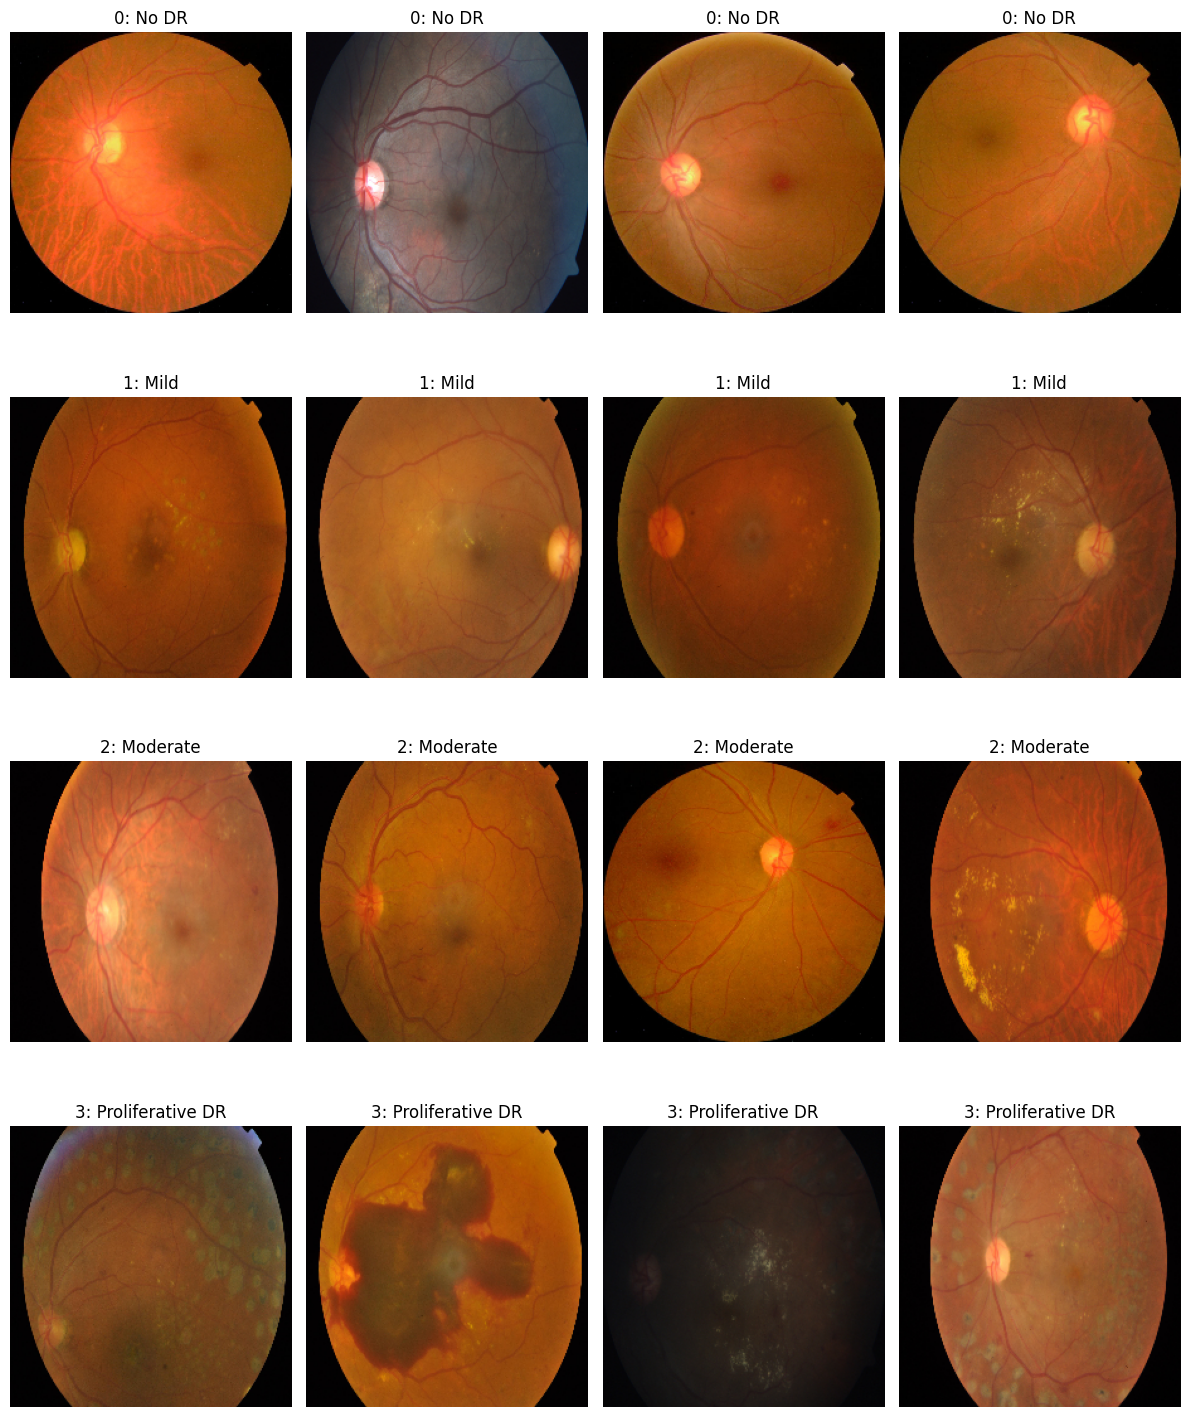

In [ ]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(12, 15))

for class_id in range(NUM_CLASSES):
    samples = df[df["diagnosis"] == class_id].sample(
        n=min(4, class_counts[class_id]),
        random_state=SEED
    )

    for col, (_, row) in enumerate(samples.iterrows()):
        image = Image.open(row["image_path"]).convert("RGB")
        axes[class_id, col].imshow(image)
        axes[class_id, col].set_title(
            f"{class_id}: {CLASS_NAMES[class_id]}"
        )
        axes[class_id, col].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_images_by_class.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## 8. Image preparation for ResNet50

The images are already stored at **224 × 224**. We keep that resolution and prepare RGB pixel values for ResNet50 using Keras `preprocess_input`.

Training augmentation is applied **only to the training split**. Validation and test images are not augmented.

In [ ]:
def load_image_for_resnet(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return tf.cast(image, tf.float32), label

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(height_factor=(-0.08, 0.08), width_factor=(-0.08, 0.08)),
    layers.RandomContrast(0.10),
], name="train_time_augmentation")

def augment_image(image, label):
    return data_augmentation(image, training=True), label

def preprocess_for_resnet(image, label):
    return keras.applications.resnet50.preprocess_input(image), label

## 9. Verify one processed image

Original shape: (224, 224, 3)
Processed shape: (224, 224, 3)
Original range: 0.0 to 255.0
ResNet-preprocessed range: -123.68 to 131.32


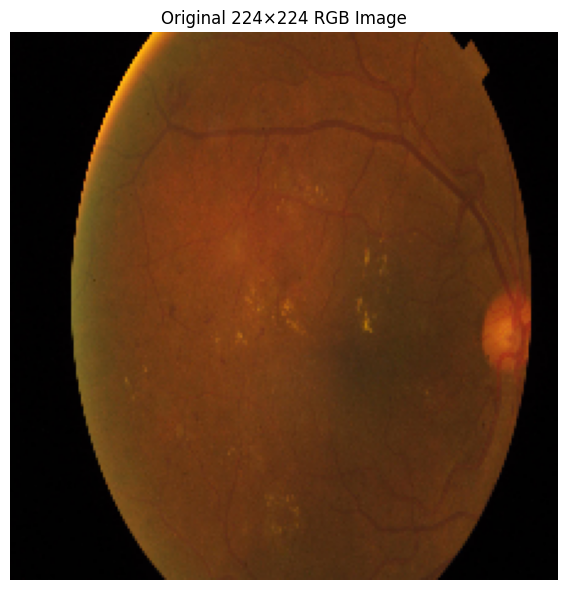

The numeric tensor above is the version passed to ResNet50; the displayed image remains in normal RGB form for visualization.


In [ ]:
sample_path = df.iloc[0]["image_path"]


raw_image = np.asarray(
    Image.open(sample_path).convert("RGB")
).astype(np.float32)


processed_image = keras.applications.resnet50.preprocess_input(
    raw_image.copy()
)


print("Original shape:", raw_image.shape)
print("Processed shape:", processed_image.shape)
print("Original range:", raw_image.min(), "to", raw_image.max())
print("ResNet-preprocessed range:", processed_image.min(), "to", processed_image.max())


plt.figure(figsize=(6, 6))
plt.imshow(raw_image.astype(np.uint8))
plt.title("Original 224×224 RGB Image")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "original_image_check.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


print("The numeric tensor above is the version passed to ResNet50; the displayed image remains in normal RGB form for visualization.")

## 10. Train / validation / test split

A **80% / 10% / 10%** stratified split is used:

- 80% training
- 10% validation
- 10% final test

The validation set is used during model development and checkpoint selection. The test set is not used for training or model selection and is evaluated only after the final model is fixed.

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["diagnosis"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["diagnosis"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images  :", len(train_df))
print("Validation images:", len(val_df))
print("Test images      :", len(test_df))
print("Total images     :", len(train_df) + len(val_df) + len(test_df))

Training images  : 2775
Validation images: 347
Test images      : 347
Total images     : 3469


In [ ]:
split_summary = pd.DataFrame({
    "Class": range(NUM_CLASSES),
    "Severity": [CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    "Train": [(train_df["diagnosis"] == i).sum() for i in range(NUM_CLASSES)],
    "Validation": [(val_df["diagnosis"] == i).sum() for i in range(NUM_CLASSES)],
    "Test": [(test_df["diagnosis"] == i).sum() for i in range(NUM_CLASSES)],
})

split_summary["Total"] = (
    split_summary["Train"] +
    split_summary["Validation"] +
    split_summary["Test"]
)

display(split_summary)

,Class,Severity,Train,Validation,Test,Total
0,0,No DR,1444,180,181,1805
1,1,Mild,296,37,37,370
2,2,Moderate,799,100,100,999
3,3,Proliferative DR,236,30,29,295


## 11. TensorFlow input pipeline

In [ ]:
def make_dataset(dataframe, shuffle=False, augment=False):
    paths = dataframe["image_path"].values
    labels = dataframe["diagnosis"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image_for_resnet,
        num_parallel_calls=AUTOTUNE,
    )

    if augment:
        dataset = dataset.map(
            augment_image,
            num_parallel_calls=AUTOTUNE,
        )

    dataset = dataset.map(
        preprocess_for_resnet,
        num_parallel_calls=AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, shuffle=True, augment=True)
val_ds = make_dataset(val_df, shuffle=False, augment=False)
test_ds = make_dataset(test_df, shuffle=False, augment=False)

print("Training batches  :", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches      :", len(test_ds))

Training batches  : 87
Validation batches: 11
Test batches      : 11


## 12. Check one training batch

In [ ]:
X_batch, y_batch = next(iter(train_ds))

print("Image batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)
print("Processed pixel range:", float(tf.reduce_min(X_batch)), "to", float(tf.reduce_max(X_batch)))
print("Labels in batch:", np.unique(y_batch.numpy()))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Processed pixel range: -123.68000030517578 to 151.06100463867188
Labels in batch: [0 1 2 3]


## 13. Training class weights


In [ ]:
train_classes = np.arange(NUM_CLASSES)
raw_weights = compute_class_weight("balanced", classes=train_classes, y=train_df["diagnosis"].values)
class_weights = {int(k): float(np.sqrt(v)) for k, v in zip(train_classes, raw_weights)}
class_weight_df = pd.DataFrame({
    "Class": train_classes,
    "Severity": [CLASS_NAMES[i] for i in train_classes],
    "Raw_balanced_weight": raw_weights,
    "Training_weight": [class_weights[i] for i in train_classes],
})
display(class_weight_df)
class_weight_df.to_csv(OUTPUT_DIR / "class_weights.csv", index=False)

,Class,Severity,Raw_balanced_weight,Training_weight
0,0,No DR,0.480436,0.693135
1,1,Mild,2.343750,1.530931
2,2,Moderate,0.868273,0.931812
3,3,Proliferative DR,2.939619,1.714532


## 13.5 Validation metrics used for model selection

- **Validation QWK** — primary checkpoint metric.
- **Validation Macro-F1** — gives each severity class equal importance.
- **Validation accuracy** — overall performance.

In [ ]:
class ValidationMetricsCallback(keras.callbacks.Callback):
    def __init__(self, val_dataset, num_classes, use_tta=True):
        super().__init__()
        self.val_dataset = val_dataset
        self.num_classes = num_classes
        self.use_tta = use_tta

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        y_true_all, y_pred_all = [], []

        for x_batch, y_batch in self.val_dataset:
            probs = self.model(x_batch, training=False)
            if self.use_tta:
                probs_flip = self.model(tf.image.flip_left_right(x_batch), training=False)
                probs = (probs + probs_flip) / 2.0
            y_true_all.append(y_batch.numpy())
            y_pred_all.append(tf.argmax(probs, axis=1).numpy())

        y_true_all = np.concatenate(y_true_all)
        y_pred_all = np.concatenate(y_pred_all)
        macro_f1 = f1_score(y_true_all, y_pred_all, average="macro", labels=list(range(self.num_classes)), zero_division=0)
        qwk = cohen_kappa_score(y_true_all, y_pred_all, weights="quadratic", labels=list(range(self.num_classes)))
        logs["val_macro_f1"] = float(macro_f1)
        logs["val_qwk"] = float(qwk)
        print(f" - val_macro_f1: {macro_f1:.4f} - val_qwk: {qwk:.4f}")

validation_metrics_cb = ValidationMetricsCallback(val_ds, NUM_CLASSES, use_tta=True)

## 14. ResNet50 model

ResNet50 is used with ImageNet-pretrained weights.
The backbone is first frozen so the new classification head can learn from the retinal dataset. A later fine-tuning stage unfreezes the final part of the ResNet50 backbone using a smaller learning rate.

In [ ]:
resnet_base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
resnet_base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="resnet_input")
features = resnet_base(inputs, training=False)
features = layers.GlobalAveragePooling2D(name="global_average_pool")(features)
features = layers.BatchNormalization(name="classifier_batch_norm")(features)
features = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4), name="classifier_dense")(features)
features = layers.Dropout(0.45, name="classifier_dropout")(features)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="severity_output")(features)

resnet_model = keras.Model(inputs, outputs, name="APTOS_ResNet50")
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "APTOS_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet_input (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_batch_norm           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ severity_output (Dense)         │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 529,668 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

## 15. Stage 1 — train the classification head


In [ ]:
BEST_MODEL_PATH = OUTPUT_DIR / "resnet50_best.keras"
TRAINING_LOG_PATH = OUTPUT_DIR / "resnet50_training_log.csv"
BACKUP_DIR = OUTPUT_DIR / "training_backup"

checkpoint_cb = keras.callbacks.ModelCheckpoint(str(BEST_MODEL_PATH), monitor="val_qwk", mode="max", save_best_only=True, verbose=1)

stage1_callbacks = [
    validation_metrics_cb,
    checkpoint_cb,
    keras.callbacks.ReduceLROnPlateau(monitor="val_qwk", mode="max", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_qwk", mode="max", patience=7, min_delta=0.002, restore_best_weights=False, verbose=1),
    keras.callbacks.TerminateOnNaN(),
    keras.callbacks.BackupAndRestore(backup_dir=str(BACKUP_DIR / "stage1"), delete_checkpoint=False),
    keras.callbacks.CSVLogger(str(TRAINING_LOG_PATH), append=False),
]

resnet_model.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=3e-4,
        weight_decay=1e-4,
        clipnorm=1.0
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
)
HEAD_EPOCHS = 20
history_head = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=stage1_callbacks,
    verbose=1,
)

Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 578ms/step - accuracy: 0.6323 - loss: 1.2271 - val_macro_f1: 0.4772 - val_qwk: 0.6732

Epoch 1: val_qwk improved from None to 0.67317, saving model to /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/CSE427_progress/resnet50_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/CSE427_progress/resnet50_best.keras
87/87 ━━━━━━━━━━━━━━━━━━━━ 90s 815ms/step - accuracy: 0.7088 - loss: 1.0327 - val_accuracy: 0.6513 - val_loss: 0.9456 - val_macro_f1: 0.4772 - val_qwk: 0.6732 - learning_rate: 3.0000e-04
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.7535 - loss: 0.8249 - val_macro_f1: 0.6200 - val_qwk: 0.8119

Epoch 2: val_qwk improved from 0.67317 to 0.81189, saving model to /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/CSE427_progress/resnet50_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_

## 16. Stage 2 — fine-tuning of upper ResNet50 layers



In [ ]:
resnet_model = keras.models.load_model(BEST_MODEL_PATH)
resnet_base = resnet_model.get_layer("resnet50")
resnet_base.trainable = True
FINE_TUNE_LAYERS = 60

for layer in resnet_base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in resnet_base.layers[-FINE_TUNE_LAYERS:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_count = sum(int(layer.trainable) for layer in resnet_base.layers)
print("Trainable ResNet50 layers:", trainable_count, "of", len(resnet_base.layers))

resnet_model.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=3e-4,
        weight_decay=1e-4,
        clipnorm=1.0
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
)

FINE_TUNE_EPOCHS = 35
INITIAL_EPOCH = len(history_head.history["loss"])
stage2_callbacks = [
    validation_metrics_cb,
    checkpoint_cb,
    keras.callbacks.ReduceLROnPlateau(monitor="val_qwk", mode="max", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_qwk", mode="max", patience=7, min_delta=0.002, restore_best_weights=False, verbose=1),
    keras.callbacks.TerminateOnNaN(),
    keras.callbacks.BackupAndRestore(backup_dir=str(BACKUP_DIR / "stage2"), delete_checkpoint=False),
    keras.callbacks.CSVLogger(str(TRAINING_LOG_PATH), append=True),
]

history_fine = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=INITIAL_EPOCH,
    epochs=INITIAL_EPOCH + FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=stage2_callbacks,
    verbose=1,
)

Trainable ResNet50 layers: 42 of 175
Epoch 16/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - accuracy: 0.7815 - loss: 0.6979 - val_macro_f1: 0.1711 - val_qwk: 0.0116

Epoch 16: val_qwk did not improve from 0.87237
87/87 ━━━━━━━━━━━━━━━━━━━━ 101s 842ms/step - accuracy: 0.7712 - loss: 0.7364 - val_accuracy: 0.5187 - val_loss: 7.5732 - val_macro_f1: 0.1711 - val_qwk: 0.0116 - learning_rate: 3.0000e-04
Epoch 17/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 566ms/step - accuracy: 0.7960 - loss: 0.6431 - val_macro_f1: 0.1808 - val_qwk: 0.2533

Epoch 17: val_qwk did not improve from 0.87237
87/87 ━━━━━━━━━━━━━━━━━━━━ 60s 684ms/step - accuracy: 0.8011 - loss: 0.6525 - val_accuracy: 0.3141 - val_loss: 3.3731 - val_macro_f1: 0.1808 - val_qwk: 0.2533 - learning_rate: 3.0000e-04
Epoch 18/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 595ms/step - accuracy: 0.8187 - loss: 0.5876 - val_macro_f1: 0.5185 - val_qwk: 0.7824

Epoch 18: val_qwk did not improve from 0.87237
87/87 ━━━━━━━━━━━━━━━━━━━━ 64s 732ms/step - accuracy: 0.8241

## 17. Load the best validation checkpoint

The final model is the checkpoint with the **highest validation QWK**. The held-out test set is not used for model selection.

In [ ]:
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(f"Best model checkpoint was not created: {BEST_MODEL_PATH}")
resnet_model = keras.models.load_model(BEST_MODEL_PATH)
print("Best ResNet50 checkpoint loaded:", BEST_MODEL_PATH)

Best ResNet50 checkpoint loaded: /content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET/CSE427_progress/resnet50_best.keras


## 18. Combined training curves

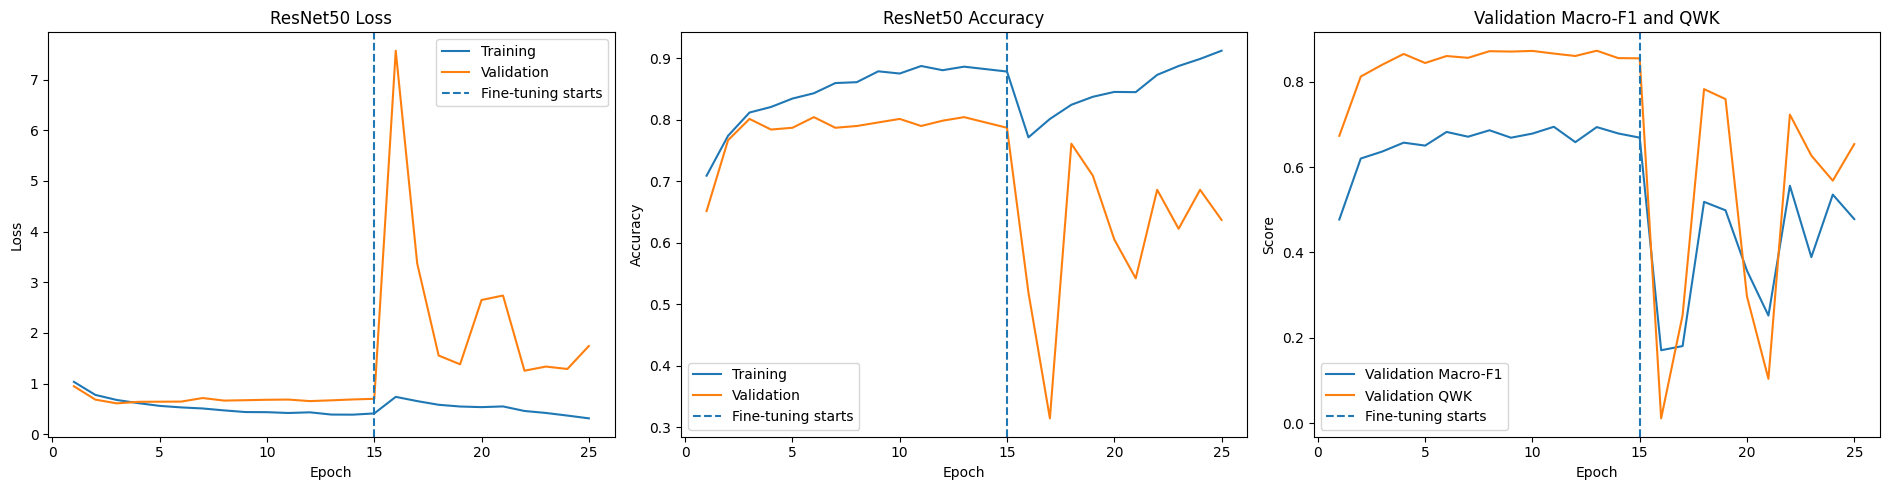

In [ ]:
history_all = {}
for key, values in history_head.history.items():
    history_all[key] = list(values)
for key, values in history_fine.history.items():
    history_all.setdefault(key, [])
    history_all[key].extend(list(values))

history_df = pd.DataFrame(history_all)
epoch_numbers = np.arange(1, len(history_df) + 1)
fine_tune_start = len(history_head.history["loss"])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].plot(epoch_numbers, history_df["loss"], label="Training")
axes[0].plot(epoch_numbers, history_df["val_loss"], label="Validation")
axes[0].axvline(fine_tune_start, linestyle="--", label="Fine-tuning starts")
axes[0].set_title("ResNet50 Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].plot(epoch_numbers, history_df["accuracy"], label="Training")
axes[1].plot(epoch_numbers, history_df["val_accuracy"], label="Validation")
axes[1].axvline(fine_tune_start, linestyle="--", label="Fine-tuning starts")
axes[1].set_title("ResNet50 Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
axes[2].plot(epoch_numbers, history_df["val_macro_f1"], label="Validation Macro-F1")
axes[2].plot(epoch_numbers, history_df["val_qwk"], label="Validation QWK")
axes[2].axvline(fine_tune_start, linestyle="--", label="Fine-tuning starts")
axes[2].set_title("Validation Macro-F1 and QWK"); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Score"); axes[2].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "resnet50_training_curves.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close()
history_df.to_csv(OUTPUT_DIR / "resnet50_training_history.csv", index=False)

## 19. Final evaluation on the held-out test set


In [ ]:
def predict_with_tta(model, dataset):
    all_probabilities = []
    for x_batch, _ in dataset:
        p1 = model(x_batch, training=False)
        p2 = model(tf.image.flip_left_right(x_batch), training=False)
        all_probabilities.append(((p1 + p2) / 2.0).numpy())
    return np.concatenate(all_probabilities, axis=0)

y_true = test_df["diagnosis"].values
y_prob_raw = np.concatenate([resnet_model(x, training=False).numpy() for x, _ in test_ds], axis=0)
y_prob_tta = predict_with_tta(resnet_model, test_ds)
y_pred_raw = np.argmax(y_prob_raw, axis=1)
y_pred = np.argmax(y_prob_tta, axis=1)

assert len(y_true) == len(y_pred)
raw_accuracy = accuracy_score(y_true, y_pred_raw)
tta_accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy (raw): {raw_accuracy:.4f}")
print(f"Test accuracy (TTA): {tta_accuracy:.4f}")

Test accuracy (raw): 0.7867
Test accuracy (TTA): 0.8184


## 20. Test-set classification report and robust metrics

accuracy, balanced accuracy, Macro-F1, Weighted-F1, QWK, ordinal MAE, and within-one accuracy

In [ ]:
from sklearn.metrics import balanced_accuracy_score, mean_absolute_error

report_text = classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    zero_division=0,
)
test_qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic", labels=list(range(NUM_CLASSES)))
test_macro_f1 = f1_score(y_true, y_pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)
test_weighted_f1 = f1_score(y_true, y_pred, average="weighted", labels=list(range(NUM_CLASSES)), zero_division=0)
test_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
test_mae = mean_absolute_error(y_true, y_pred)
test_within_one = float(np.mean(np.abs(y_true - y_pred) <= 1))

print(report_text)
print(f"Test accuracy (TTA): {tta_accuracy:.4f}")
print(f"Balanced accuracy  : {test_balanced_accuracy:.4f}")
print(f"Macro-F1           : {test_macro_f1:.4f}")
print(f"Weighted-F1        : {test_weighted_f1:.4f}")
print(f"QWK                : {test_qwk:.4f}")
print(f"Ordinal MAE        : {test_mae:.4f}")
print(f"Within-one accuracy: {test_within_one:.4f}")

with open(OUTPUT_DIR / "resnet50_test_classification_report.txt", "w", encoding="utf-8") as f:
    f.write(report_text)
    f.write(f"\nTest accuracy (raw): {raw_accuracy:.4f}\n")
    f.write(f"Test accuracy (TTA): {tta_accuracy:.4f}\n")
    f.write(f"Balanced accuracy: {test_balanced_accuracy:.4f}\n")
    f.write(f"Macro-F1: {test_macro_f1:.4f}\n")
    f.write(f"Weighted-F1: {test_weighted_f1:.4f}\n")
    f.write(f"Quadratic Weighted Kappa (QWK): {test_qwk:.4f}\n")
    f.write(f"Ordinal MAE: {test_mae:.4f}\n")
    f.write(f"Within-one accuracy: {test_within_one:.4f}\n")

                  precision    recall  f1-score   support

           No DR       0.95      0.98      0.97       181
            Mild       0.49      0.51      0.50        37
        Moderate       0.78      0.71      0.74       100
Proliferative DR       0.53      0.55      0.54        29

        accuracy                           0.82       347
       macro avg       0.69      0.69      0.69       347
    weighted avg       0.82      0.82      0.82       347

Test accuracy (TTA): 0.8184
Balanced accuracy  : 0.6897
Macro-F1           : 0.6883
Weighted-F1        : 0.8175
QWK                : 0.8975
Ordinal MAE        : 0.1988
Within-one accuracy: 0.9827


## 21. Bootstrap confidence intervals for the final test metrics

The held-out test set is a single sample, so we also estimate 95% bootstrap confidence intervals for accuracy and QWK. This gives a sense of uncertainty around the reported test metrics without retraining the model.

In [ ]:
BOOTSTRAP_SEED = 42
BOOTSTRAP_ROUNDS = 1000
rng = np.random.default_rng(BOOTSTRAP_SEED)

boot_accuracy = []
boot_qwk = []
indices = np.arange(len(y_true))

for _ in range(BOOTSTRAP_ROUNDS):
    sample_idx = rng.choice(indices, size=len(indices), replace=True)
    yt = y_true[sample_idx]
    yp = y_pred[sample_idx]
    boot_accuracy.append(accuracy_score(yt, yp))
    boot_qwk.append(cohen_kappa_score(yt, yp, weights="quadratic", labels=list(range(NUM_CLASSES))))

accuracy_ci = np.percentile(boot_accuracy, [2.5, 97.5])
qwk_ci = np.percentile(boot_qwk, [2.5, 97.5])

print(f"Test accuracy 95% CI: [{accuracy_ci[0]:.4f}, {accuracy_ci[1]:.4f}]")
print(f"Test QWK 95% CI     : [{qwk_ci[0]:.4f}, {qwk_ci[1]:.4f}]")

pd.DataFrame({
    "metric": ["test_accuracy_tta", "test_qwk"],
    "point_estimate": [tta_accuracy, test_qwk],
    "ci_lower_95": [accuracy_ci[0], qwk_ci[0]],
    "ci_upper_95": [accuracy_ci[1], qwk_ci[1]],
}).to_csv(OUTPUT_DIR / "test_metric_bootstrap_ci.csv", index=False)

Test accuracy 95% CI: [0.7780, 0.8559]
Test QWK 95% CI     : [0.8684, 0.9247]


## 21. Test-set confusion matrix

The matrix uses the final TTA predictions. Diagonal cells are correct predictions; off-diagonal cells show which severity levels are being confused.

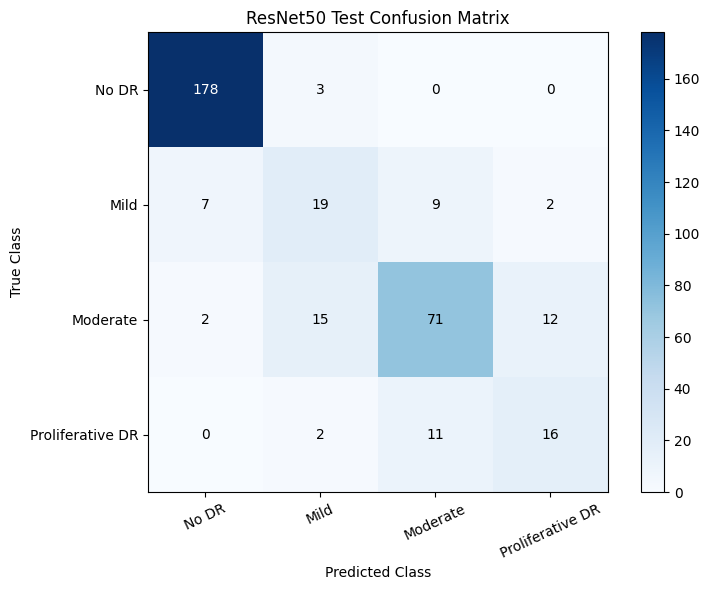

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)

plt.figure(figsize=(8, 6))
im = plt.imshow(cm, interpolation="nearest", cmap="Blues")

plt.title("ResNet50 Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(NUM_CLASSES),
    [CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    rotation=25,
)
plt.yticks(
    range(NUM_CLASSES),
    [CLASS_NAMES[i] for i in range(NUM_CLASSES)],
)

threshold = cm.max() / 2.0

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
        )

plt.colorbar(im)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "resnet50_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

np.savetxt(
    OUTPUT_DIR / "resnet50_test_confusion_matrix.csv",
    cm,
    delimiter=",",
    fmt="%d",
)

## 22. Save test predictions


In [ ]:
test_predictions = test_df[["id_code", "diagnosis"]].copy()
test_predictions["predicted_diagnosis_raw"] = y_pred_raw
test_predictions["predicted_diagnosis_tta"] = y_pred
test_predictions["predicted_label"] = [CLASS_NAMES[int(x)] for x in y_pred]
test_predictions["true_label"] = [CLASS_NAMES[int(x)] for x in y_true]
test_predictions["confidence_tta"] = y_prob_tta.max(axis=1)
test_predictions["correct_tta"] = y_pred == y_true
test_predictions.to_csv(OUTPUT_DIR / "resnet50_test_predictions.csv", index=False)
display(test_predictions.head())

## 23. Grad-CAM setup



ResNet50 backbone: resnet50
Grad-CAM layer: conv5_block3_3_conv
Grad-CAM feature shape: (None, 7, 7, 2048)


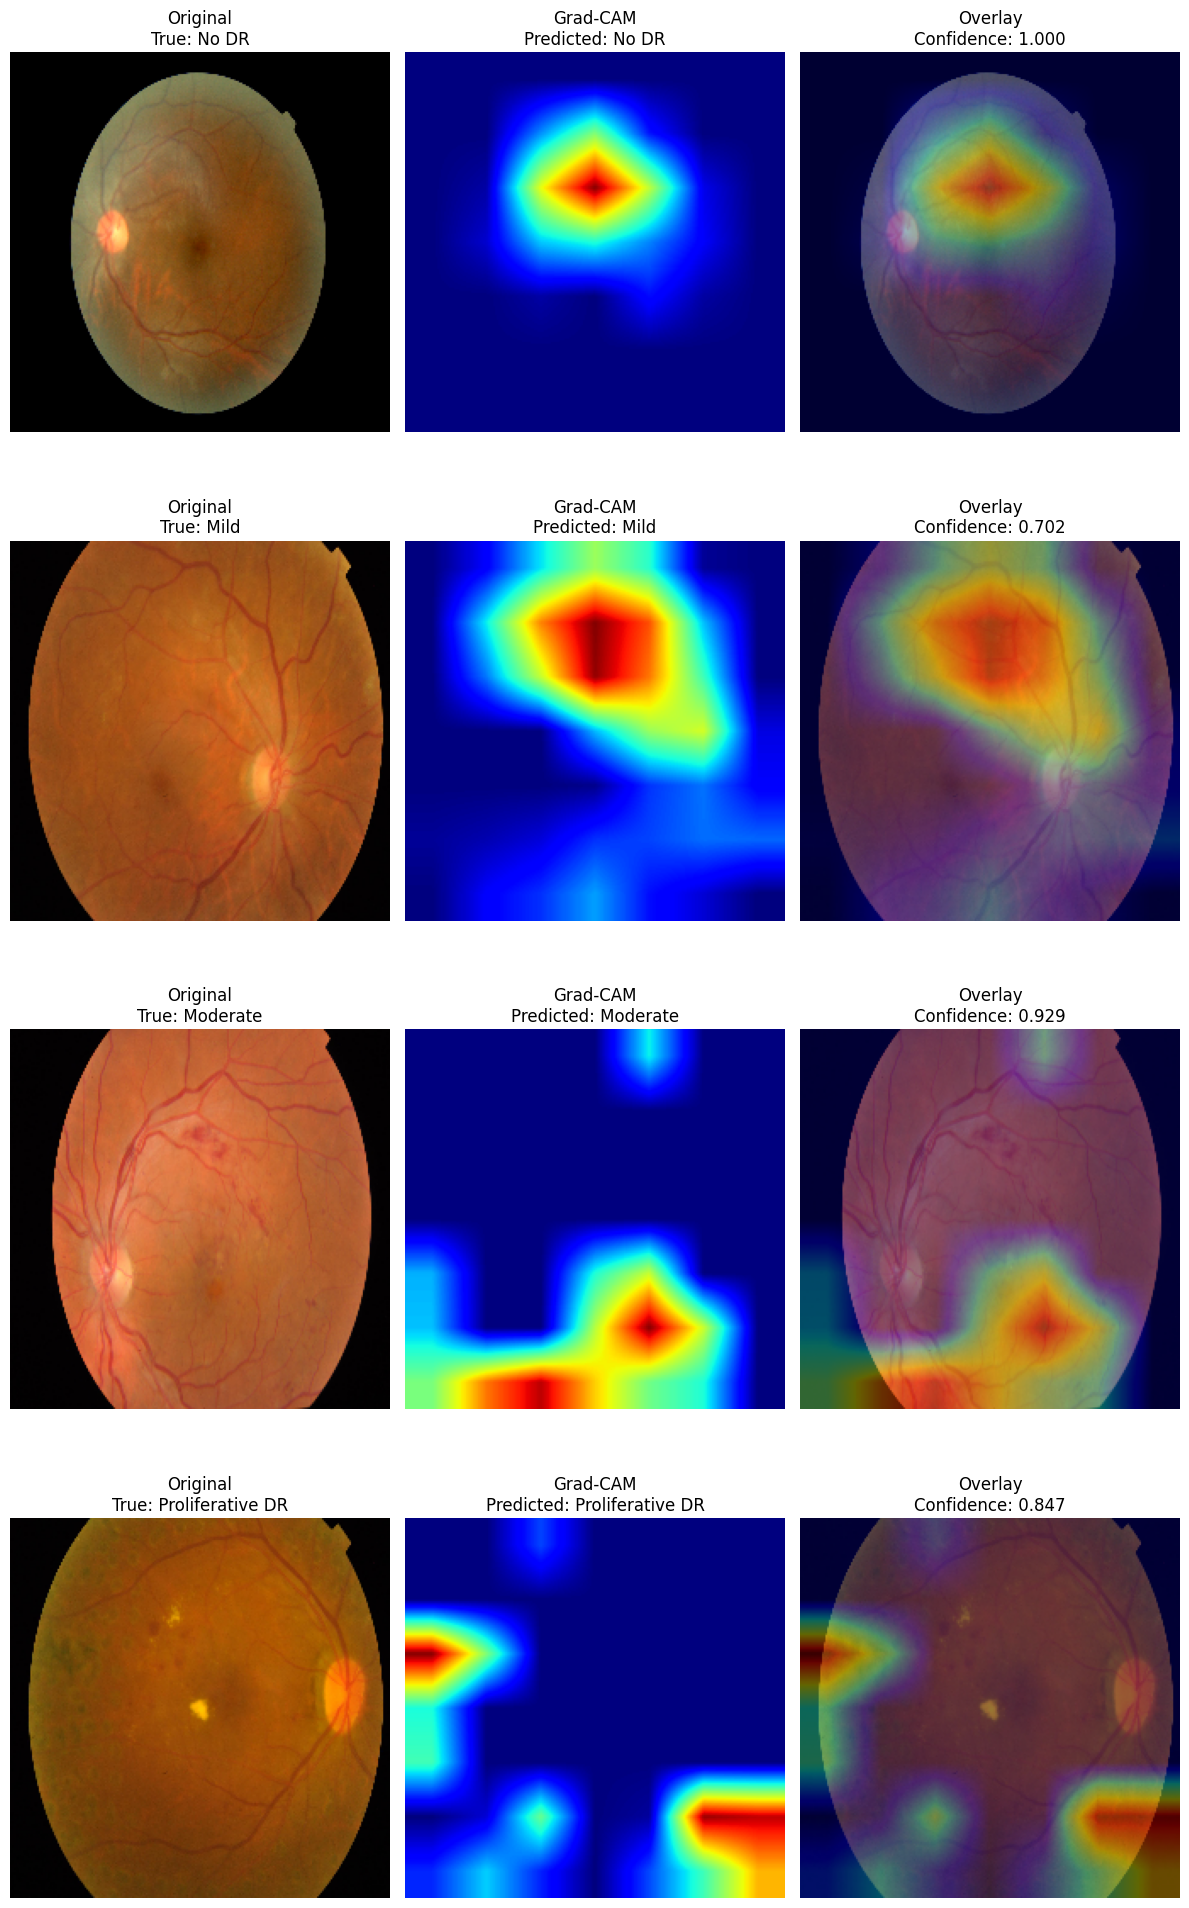

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from pathlib import Path
import os
import shutil


if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")


PROJECT_DIR = Path(
    "/content/drive/MyDrive/427resourcesPRETOM/PROJECT_APTOS_DATASET"
)

OUTPUT_DIR = PROJECT_DIR / "CSE427_progress"
EXTRACT_DIR = PROJECT_DIR / "APTOS_extracted"

LOCAL_DATASET_DIR = Path("/content/APTOS_local")
LOCAL_IMAGE_ROOT = LOCAL_DATASET_DIR / "colored_images"

IMG_SIZE = 224

CLASS_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Proliferative DR",
}

NUM_CLASSES = len(CLASS_NAMES)

NUM_CLASSES = len(CLASS_NAMES)


if not LOCAL_IMAGE_ROOT.exists():

    print("Local dataset not found. Restoring from Drive...")

    LOCAL_DATASET_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    SOURCE_IMAGE_ROOT = EXTRACT_DIR / "colored_images"

    if SOURCE_IMAGE_ROOT.exists():

        shutil.copytree(
            SOURCE_IMAGE_ROOT,
            LOCAL_IMAGE_ROOT
        )

        print("Dataset restored to local storage.")

    else:

        raise FileNotFoundError(
            f"Source images not found at {SOURCE_IMAGE_ROOT}"
        )


if "test_df" not in locals():

    TEST_CSV_PATH = OUTPUT_DIR / "test_split.csv"

    if TEST_CSV_PATH.exists():

        test_df = pd.read_csv(
            TEST_CSV_PATH
        )

    else:

        raise FileNotFoundError(
            f"Test split not found at {TEST_CSV_PATH}"
        )



if "resnet_model" not in locals():

    BEST_MODEL_PATH = (
        OUTPUT_DIR /
        "resnet50_best.keras"
    )

    if not BEST_MODEL_PATH.exists():

        raise FileNotFoundError(
            f"Model checkpoint not found at {BEST_MODEL_PATH}"
        )

    resnet_model = tf.keras.models.load_model(
        BEST_MODEL_PATH
    )
def prepare_image_for_model(path):

    image = Image.open(path).convert("RGB")

    image = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.asarray(
        image
    ).astype(np.float32)
    original_rgb = image_array.copy()

    model_input = (
        tf.keras.applications.resnet50.preprocess_input(
            image_array.copy()
        )
    )

    model_input = np.expand_dims(
        model_input,
        axis=0
    )

    return original_rgb, model_input

backbone = resnet_model.get_layer(
    "resnet50"
)

print(
    "ResNet50 backbone:",
    backbone.name
)


last_conv_layer = None

for layer in reversed(backbone.layers):

    if isinstance(
        layer,
        tf.keras.layers.Conv2D
    ):

        last_conv_layer = layer
        break


if last_conv_layer is None:

    raise ValueError(
        "Could not locate the final Conv2D layer."
    )


print(
    "Grad-CAM layer:",
    last_conv_layer.name
)

print(
    "Grad-CAM feature shape:",
    last_conv_layer.output.shape
)


global_pool_layer = resnet_model.get_layer(
    "global_average_pool"
)

batch_norm_layer = resnet_model.get_layer(
    "classifier_batch_norm"
)

dense_layer = resnet_model.get_layer(
    "classifier_dense"
)

output_layer = resnet_model.get_layer(
    "severity_output"
)


backbone_grad_model = tf.keras.models.Model(
    inputs=backbone.input,
    outputs=[
        last_conv_layer.output,
        backbone.output
    ]
)


def make_gradcam_heatmap(
    model_input,
    target_class
):

    image_tensor = tf.cast(
        model_input,
        tf.float32
    )

    with tf.GradientTape() as tape:

        conv_outputs, backbone_features = (
            backbone_grad_model(
                image_tensor,
                training=False
            )
        )

        x = global_pool_layer(
            backbone_features,
            training=False
        )

        x = batch_norm_layer(
            x,
            training=False
        )

        x = dense_layer(
            x,
            training=False
        )

        predictions = output_layer(
            x,
            training=False
        )

        class_score = predictions[
            :,
            target_class
        ]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    if gradients is None:

        raise RuntimeError(
            "Gradients could not be calculated. "
            "Check the Grad-CAM layer and model graph."
        )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_gradients = pooled_gradients[0]


    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )


    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy()



def overlay_heatmap(
    original_rgb,
    heatmap,
    alpha=0.4
):

    heatmap_resized = (
        tf.image.resize(
            heatmap[..., np.newaxis],
            [IMG_SIZE, IMG_SIZE]
        )
        .numpy()[:, :, 0]
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_color = (
        plt.cm.jet(
            heatmap_uint8
        )[:, :, :3]
        * 255
    )

    heatmap_color = np.uint8(
        heatmap_color
    )


    original_uint8 = np.clip(
        original_rgb,
        0,
        255
    ).astype(np.uint8)

    # Overlay
    overlay = (
        original_uint8 * (1 - alpha)
        +
        heatmap_color * alpha
    ).astype(np.uint8)

    return (
        original_uint8,
        heatmap_color,
        overlay
    )

#Grad-CAM visualizations


fig, axes = plt.subplots(
    NUM_CLASSES,
    3,
    figsize=(12, 5 * NUM_CLASSES)
)

if NUM_CLASSES == 1:

    axes = np.expand_dims(
        axes,
        axis=0
    )


for class_id in range(NUM_CLASSES):

    class_rows = test_df[
        test_df["diagnosis"] == class_id
    ]

    if len(class_rows) == 0:

        print(
            f"Warning: No test image found "
            f"for class {class_id}."
        )

        continue


    row = class_rows.iloc[0]

    original_rgb, model_input = (
        prepare_image_for_model(
            row["image_path"]
        )
    )

    probabilities = (
        resnet_model.predict(
            model_input,
            verbose=0
        )[0]
    )

    predicted_class = int(
        np.argmax(probabilities)
    )

    confidence = float(
        probabilities[predicted_class]
    )


    heatmap = make_gradcam_heatmap(
        model_input,
        target_class=predicted_class
    )

    original_vis, heatmap_vis, overlay_vis = (
        overlay_heatmap(
            original_rgb,
            heatmap
        )
    )



    axes[class_id, 0].imshow(
        original_vis
    )

    axes[class_id, 0].set_title(
        f"Original\n"
        f"True: {CLASS_NAMES[class_id]}"
    )

    axes[class_id, 0].axis("off")



    axes[class_id, 1].imshow(
        heatmap_vis
    )

    axes[class_id, 1].set_title(
        f"Grad-CAM\n"
        f"Predicted: {CLASS_NAMES[predicted_class]}"
    )

    axes[class_id, 1].axis("off")



    axes[class_id, 2].imshow(
        overlay_vis
    )

    axes[class_id, 2].set_title(
        f"Overlay\n"
        f"Confidence: {confidence:.3f}"
    )

    axes[class_id, 2].axis("off")



plt.tight_layout()

plt.show()


## 24. Final experiment outputs [Saving]

figures, tables, model checkpoints, predictions, classification report, and Grad-CAM results

In [ ]:
train_df.assign(split="train").to_csv(OUTPUT_DIR / "train_split.csv", index=False)
val_df.assign(split="validation").to_csv(OUTPUT_DIR / "validation_split.csv", index=False)
test_df.assign(split="test").to_csv(OUTPUT_DIR / "test_split.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "resnet50_training_history.csv", index=False)

FINAL_MODEL_PATH = OUTPUT_DIR / "resnet50_final.keras"
resnet_model.save(FINAL_MODEL_PATH)

best_val_qwk = float(history_df["val_qwk"].max())
best_val_macro_f1 = float(history_df["val_macro_f1"].max())
best_val_accuracy = float(history_df["val_accuracy"].max())

final_metrics = pd.DataFrame({
    "metric": [
        "test_accuracy_raw", "test_accuracy_tta", "test_balanced_accuracy",
        "test_macro_f1", "test_weighted_f1", "test_qwk", "test_ordinal_mae",
        "test_within_one_accuracy", "best_validation_accuracy",
        "best_validation_macro_f1", "best_validation_qwk",
    ],
    "value": [
        float(raw_accuracy), float(tta_accuracy), float(test_balanced_accuracy),
        float(test_macro_f1), float(test_weighted_f1), float(test_qwk), float(test_mae),
        float(test_within_one), best_val_accuracy, best_val_macro_f1, best_val_qwk,
    ],
})
final_metrics.to_csv(OUTPUT_DIR / "resnet50_final_metrics.csv", index=False)

with open(OUTPUT_DIR / "experiment_summary.txt", "w", encoding="utf-8") as f:
    f.write("=================================================\n")
    f.write(f"Total images: {len(df)}\nTraining: {len(train_df)}\nValidation: {len(val_df)}\nTest: {len(test_df)}\n")
    f.write("Split: 80% train / 10% validation / 10% test\n")
    f.write("Model: ResNet50 with ImageNet-pretrained weights\n")
    f.write("Augmentation: horizontal flip, small rotation, zoom, contrast (training only)\n")
    f.write("Imbalance handling: softened training-set class weights\n")
    f.write("Optimization: AdamW, two-stage transfer learning/fine-tuning, validation-QWK checkpointing\n")
    f.write(f"Best validation accuracy: {best_val_accuracy:.4f}\nBest validation Macro-F1: {best_val_macro_f1:.4f}\nBest validation QWK: {best_val_qwk:.4f}\n")
    f.write(f"Test accuracy (raw): {raw_accuracy:.4f}\nTest accuracy (TTA): {tta_accuracy:.4f}\n")
    f.write(f"Test balanced accuracy: {test_balanced_accuracy:.4f}\nTest Macro-F1: {test_macro_f1:.4f}\nTest Weighted-F1: {test_weighted_f1:.4f}\nTest QWK: {test_qwk:.4f}\n")
    f.write(f"Test ordinal MAE: {test_mae:.4f}\nTest within-one accuracy: {test_within_one:.4f}\n")

print("Progress and outputs saved to:", OUTPUT_DIR)

## 25. Create a downloadable results bundle

In [ ]:
BUNDLE_PATH = PROJECT_DIR / "CSE427_APTOS_ResNet50_optimized_results.zip"
if BUNDLE_PATH.exists():
    BUNDLE_PATH.unlink()
shutil.make_archive(base_name=str(BUNDLE_PATH.with_suffix("")), format="zip", root_dir=OUTPUT_DIR)
print("Results bundle:", BUNDLE_PATH)

In [ ]:
from google.colab import files
files.download(str(BUNDLE_PATH))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>